In [3]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print(root)
    if len(files) > 0:
        print(files[:5])

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/emmarex
/kaggle/input/datasets/emmarex/plantdisease
/kaggle/input/datasets/emmarex/plantdisease/PlantVillage
/kaggle/input/datasets/emmarex/plantdisease/PlantVillage/Pepper__bell___Bacterial_spot
['0f72db9c-d635-4415-9781-68937328aed2___NREC_B.Spot 9188.JPG', '1b8d3e98-43d9-441d-93ef-a359e6e9ddc2___NREC_B.Spot 9052.JPG', 'b6d35d21-4812-4e32-ab9a-b6ddda8cbb79___JR_B.Spot 8972.JPG', 'e4e7e5a2-5aa1-4378-833d-9142358c7c9b___JR_B.Spot 9092.JPG', '8b50f2db-cbf2-4758-bea6-a011f0cc1497___JR_B.Spot 3235.JPG']
/kaggle/input/datasets/emmarex/plantdisease/PlantVillage/Potato___healthy
['7948ada9-eabc-4cb7-a579-b73e938eb716___RS_HL 4185.JPG', 'f5bd2732-197b-4d8e-bb50-a4966dc416f5___RS_HL 1840.JPG', '5a3fc4bb-a78c-4276-8934-f0b037ffb860___RS_HL 5412.JPG', '875d6ded-5f01-495c-a945-ad2e17f87f91___RS_HL 1848.JPG', '4ae82355-6885-40e7-9807-dabe46ed3441___RS_HL 5410.JPG']
/kaggle/input/datasets/emmarex/plantdisease/PlantVillage/Tomato_Leaf_Mold


In [4]:
DATASET_PATH = "/kaggle/input/datasets/emmarex/plantdisease/PlantVillage"

classes = os.listdir(DATASET_PATH)

print("Total classes:", len(classes))
print(classes)

Total classes: 15
['Pepper__bell___Bacterial_spot', 'Potato___healthy', 'Tomato_Leaf_Mold', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato_Bacterial_spot', 'Tomato_Septoria_leaf_spot', 'Tomato_healthy', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato_Early_blight', 'Tomato__Target_Spot', 'Pepper__bell___healthy', 'Potato___Late_blight', 'Tomato_Late_blight', 'Potato___Early_blight', 'Tomato__Tomato_mosaic_virus']


In [5]:
import tensorflow as tf

print("GPU:", tf.config.list_physical_devices("GPU"))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [6]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

model = models.Sequential([
    data_augmentation,
    layers.Rescaling(1./127.5, offset=-1),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(15, activation="softmax")
])

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [7]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [8]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor="val_accuracy",
    patience=2,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=1,
    min_lr=0.00001
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 54s 89ms/step - accuracy: 0.7391 - loss: 0.8465 - val_accuracy: 0.8541 - val_loss: 0.4650 - learning_rate: 0.0010
Epoch 2/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 36s 70ms/step - accuracy: 0.8529 - loss: 0.4581 - val_accuracy: 0.8745 - val_loss: 0.3832 - learning_rate: 0.0010
Epoch 3/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 35s 68ms/step - accuracy: 0.8720 - loss: 0.3922 - val_accuracy: 0.8859 - val_loss: 0.3429 - learning_rate: 0.0010
Epoch 4/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 35s 69ms/step - accuracy: 0.8823 - loss: 0.3513 - val_accuracy: 0.8941 - val_loss: 0.3145 - learning_rate: 0.0010
Epoch 5/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 35s 68ms/step - accuracy: 0.8887 - loss: 0.3351 - val_accuracy: 0.8934 - val_loss: 0.3072 - learning_rate: 0.0010


In [9]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names

print("Number of classes:", len(class_names))
print(class_names)

Found 20638 files belonging to 15 classes.
Using 16511 files for training.
Found 20638 files belonging to 15 classes.
Using 4127 files for validation.
Number of classes: 15
['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


In [10]:
import tensorflow as tf

DATASET_PATH = "/kaggle/input/datasets/emmarex/plantdisease/PlantVillage"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names

print("Number of classes:", len(class_names))
print(class_names)

Found 20638 files belonging to 15 classes.
Using 16511 files for training.
Found 20638 files belonging to 15 classes.
Using 4127 files for validation.
Number of classes: 15
['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


In [11]:
print(model)

<Sequential name=sequential_1, built=True>


In [12]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

model = models.Sequential([
    data_augmentation,
    layers.Rescaling(1./127.5, offset=-1),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(len(class_names), activation="softmax")
])

# Model ko explicitly build karna
model.build((None, 224, 224, 3))

print(model)

<Sequential name=sequential_3, built=True>


In [13]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [14]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor="val_accuracy",
    patience=2,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=1,
    min_lr=0.00001
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 42s 72ms/step - accuracy: 0.7369 - loss: 0.8427 - val_accuracy: 0.8481 - val_loss: 0.4728 - learning_rate: 0.0010
Epoch 2/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 35s 68ms/step - accuracy: 0.8553 - loss: 0.4495 - val_accuracy: 0.8750 - val_loss: 0.3799 - learning_rate: 0.0010
Epoch 3/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 35s 67ms/step - accuracy: 0.8735 - loss: 0.3876 - val_accuracy: 0.8847 - val_loss: 0.3440 - learning_rate: 0.0010
Epoch 4/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.8814 - loss: 0.3567

KeyboardInterrupt: 

In [ ]:
model.save("/kaggle/working/plant_disease_mobilenetv2_best.keras")

print("Backup model saved successfully!")

In [ ]:
base_model.trainable = True

# Sirf last 30 layers train honge
for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fine-tuning setup complete!")

In [ ]:
fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3,
    callbacks=[
        EarlyStopping(
            monitor="val_accuracy",
            patience=1,
            restore_best_weights=True
        )
    ]
)

In [ ]:
model.save("/kaggle/working/plant_disease_mobilenetv2_final.keras")

print("Final model saved successfully!")

In [ ]:
import numpy as np
from sklearn.metrics import classification_report

y_true = []
y_pred = []

for images, labels in val_ds:
    predictions = model.predict(images, verbose=0)
    
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

In [15]:
print("val_ds exists:", "val_ds" in globals())
print("DATASET_PATH exists:", "DATASET_PATH" in globals())
print("IMG_SIZE exists:", "IMG_SIZE" in globals())
print("BATCH_SIZE exists:", "BATCH_SIZE" in globals())
print("SEED exists:", "SEED" in globals())

val_ds exists: True
DATASET_PATH exists: True
IMG_SIZE exists: True
BATCH_SIZE exists: True
SEED exists: True


In [16]:

print("DATASET_PATH:", DATASET_PATH)

print("IMG_SIZE:", IMG_SIZE)
print("BATCH_SIZE:", BATCH_SIZE)
print("SEED:", SEED)

print("Dataset folders:")
import os
print(os.listdir(DATASET_PATH)[:10])


DATASET_PATH: /kaggle/input/datasets/emmarex/plantdisease/PlantVillage
IMG_SIZE: (224, 224)
BATCH_SIZE: 32
SEED: 42
Dataset folders:
['Pepper__bell___Bacterial_spot', 'Potato___healthy', 'Tomato_Leaf_Mold', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato_Bacterial_spot', 'Tomato_Septoria_leaf_spot', 'Tomato_healthy', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato_Early_blight', 'Tomato__Target_Spot']


In [17]:

import tensorflow as tf

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

print("Training dataset created successfully")
print("Validation dataset created successfully")


Found 20638 files belonging to 15 classes.
Using 16511 files for training.
Found 20638 files belonging to 15 classes.
Using 4127 files for validation.
Training dataset created successfully
Validation dataset created successfully


In [18]:

print("Model exists:", "model" in globals())

if "model" in globals():
    model.summary()


Model exists: True


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │        19,215 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,315,631 (8.83 MB)

 Trainable params: 19,215 (75.06 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 38,432 (150.13 KB)

In [2]:

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")


NameError: name 'model' is not defined

In [3]:

print("TensorFlow:", "tf" in globals())
print("train_ds:", "train_ds" in globals())
print("val_ds:", "val_ds" in globals())
print("model:", "model" in globals())


TensorFlow: False
train_ds: False
val_ds: False
model: False


In [4]:

import os
import tensorflow as tf

DATASET_PATH = "/kaggle/input/datasets/emmarex/plantdisease/PlantVillage"
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

print("TensorFlow version:", tf.__version__)
print("Dataset exists:", os.path.exists(DATASET_PATH))
print("Number of classes:", len(os.listdir(DATASET_PATH)))


TensorFlow version: 2.20.0
Dataset exists: True
Number of classes: 15


In [5]:

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names

print("Training and validation datasets restored!")


Found 20638 files belonging to 15 classes.
Using 16511 files for training.


I0000 00:00:1792147792.709183      59 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792147792.712787      59 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 20638 files belonging to 15 classes.
Using 4127 files for validation.
Training and validation datasets restored!


In [6]:

from tensorflow.keras import layers, models

NUM_CLASSES = len(class_names)

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
])

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model created and compiled successfully!")
print("Number of classes:", NUM_CLASSES)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Model created and compiled successfully!
Number of classes: 15


In [7]:

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)


Epoch 1/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 75s 129ms/step - accuracy: 0.7517 - loss: 0.8035 - val_accuracy: 0.8612 - val_loss: 0.4353
Epoch 2/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 33s 63ms/step - accuracy: 0.8594 - loss: 0.4339 - val_accuracy: 0.8859 - val_loss: 0.3451
Epoch 3/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 34s 65ms/step - accuracy: 0.8817 - loss: 0.3615 - val_accuracy: 0.8905 - val_loss: 0.3257
Epoch 4/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 34s 67ms/step - accuracy: 0.8907 - loss: 0.3282 - val_accuracy: 0.9053 - val_loss: 0.2868
Epoch 5/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 37s 71ms/step - accuracy: 0.8971 - loss: 0.3089 - val_accuracy: 0.9087 - val_loss: 0.2725


In [8]:

model.save("/kaggle/working/plant_disease_model.keras")

print("Model saved successfully!")


Model saved successfully!


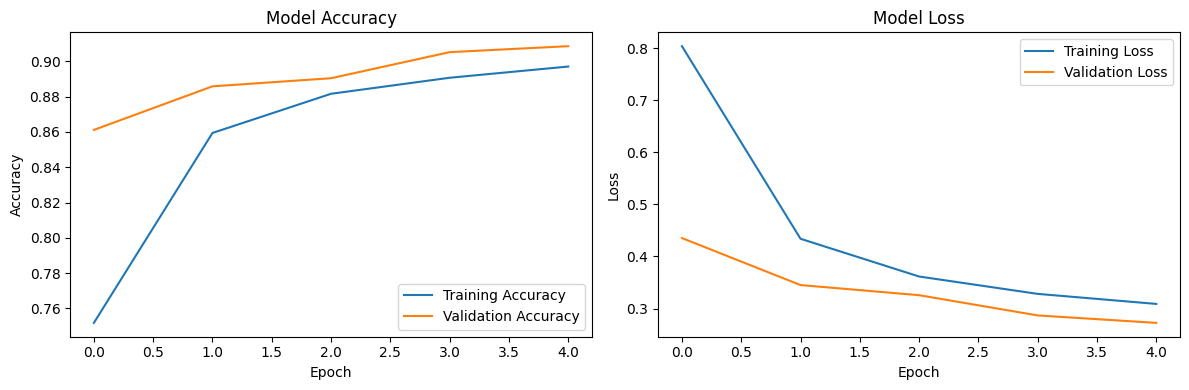

In [9]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


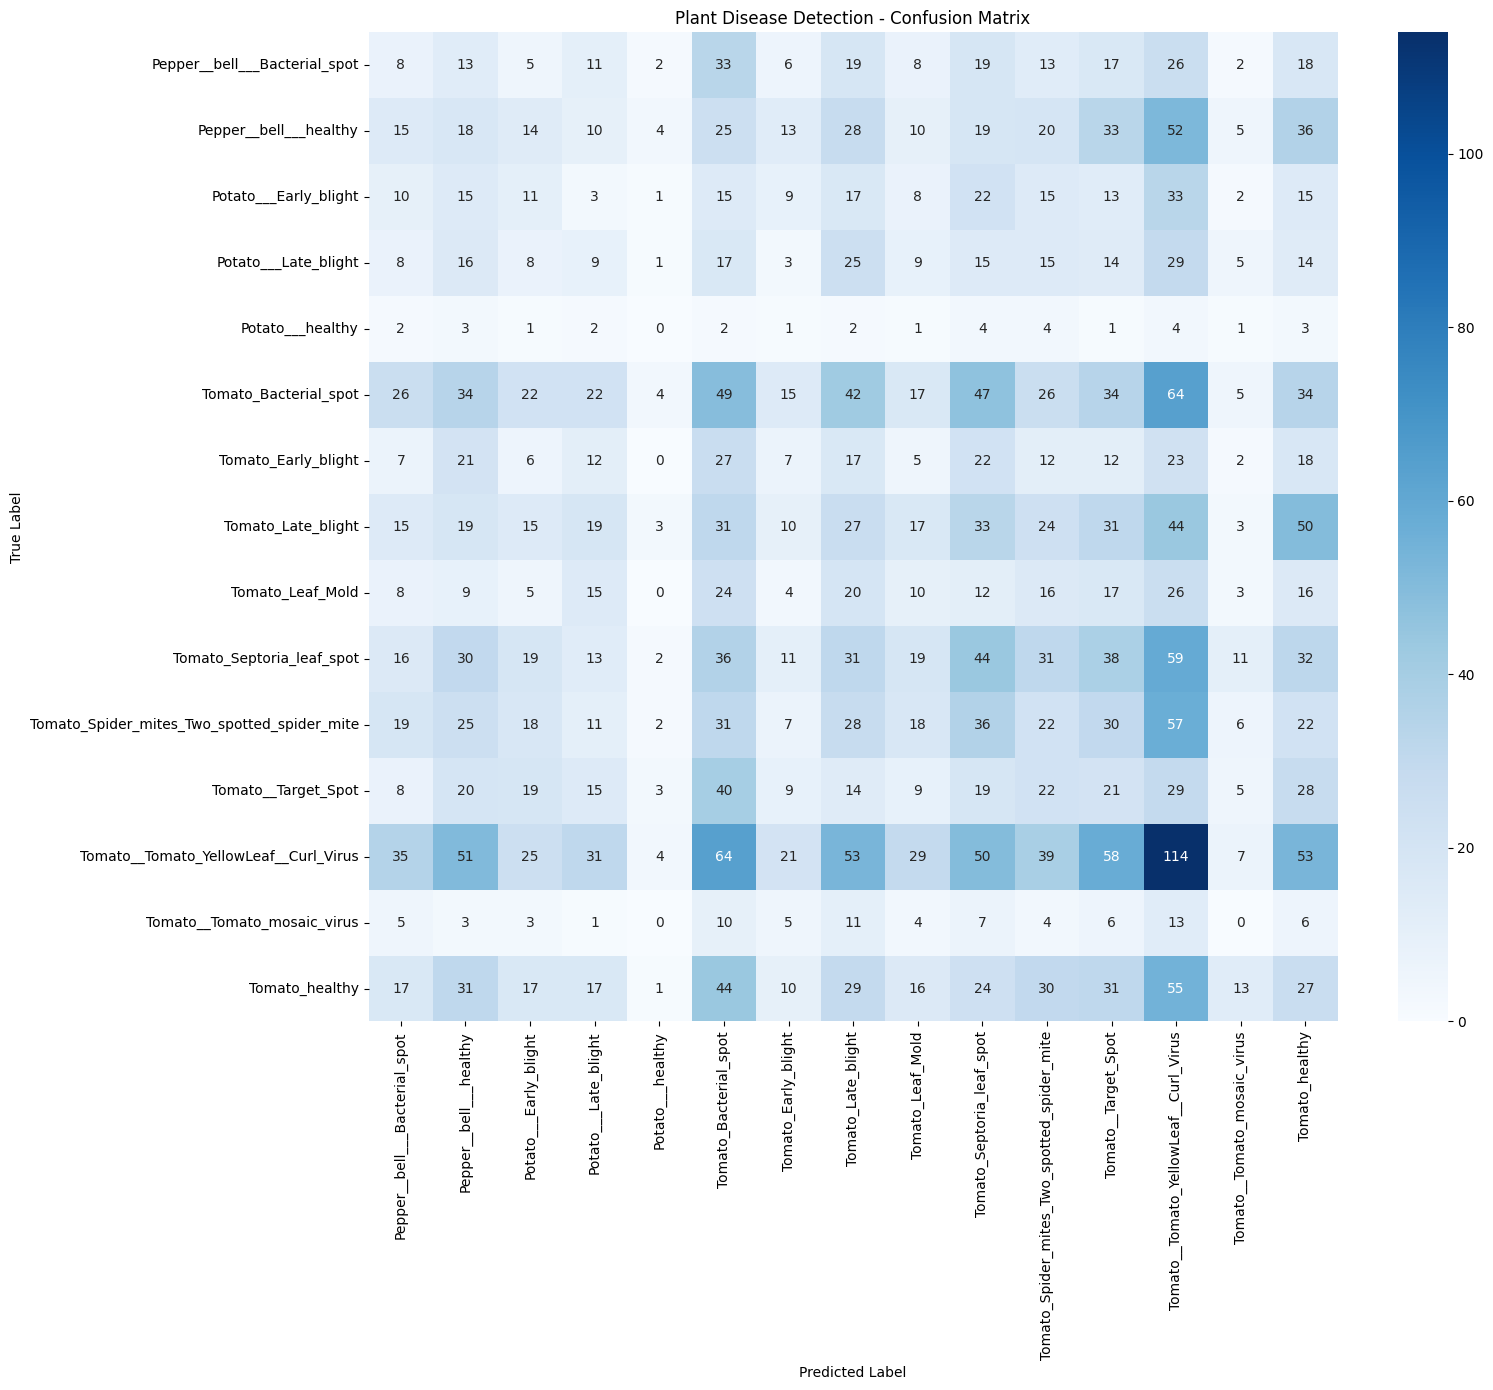

                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.04      0.04      0.04       200
                     Pepper__bell___healthy       0.06      0.06      0.06       302
                      Potato___Early_blight       0.06      0.06      0.06       189
                       Potato___Late_blight       0.05      0.05      0.05       188
                           Potato___healthy       0.00      0.00      0.00        31
                      Tomato_Bacterial_spot       0.11      0.11      0.11       441
                        Tomato_Early_blight       0.05      0.04      0.04       191
                         Tomato_Late_blight       0.07      0.08      0.08       341
                           Tomato_Leaf_Mold       0.06      0.05      0.05       185
                  Tomato_Septoria_leaf_spot       0.12      0.11      0.12       392
Tomato_Spider_mites_Two_spotted_spider_mite       0.08      0.07

In [10]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

y_true = np.concatenate([
    labels.numpy() for images, labels in val_ds
])

y_pred = np.concatenate([
    np.argmax(model.predict(images, verbose=0), axis=1)
    for images, labels in val_ds
])

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(16, 14))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Plant Disease Detection - Confusion Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))


Correct evaluation accuracy: 0.9086503513448025
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.97      0.97      0.97       200
                     Pepper__bell___healthy       0.97      0.99      0.98       302
                      Potato___Early_blight       0.99      0.98      0.99       189
                       Potato___Late_blight       0.94      0.95      0.94       188
                           Potato___healthy       0.96      0.84      0.90        31
                      Tomato_Bacterial_spot       0.91      0.92      0.91       441
                        Tomato_Early_blight       0.86      0.59      0.70       191
                         Tomato_Late_blight       0.88      0.94      0.91       341
                           Tomato_Leaf_Mold       0.89      0.87      0.88       185
                  Tomato_Septoria_leaf_spot       0.89      0.84      0.87       392
Tomato_Spider_mi

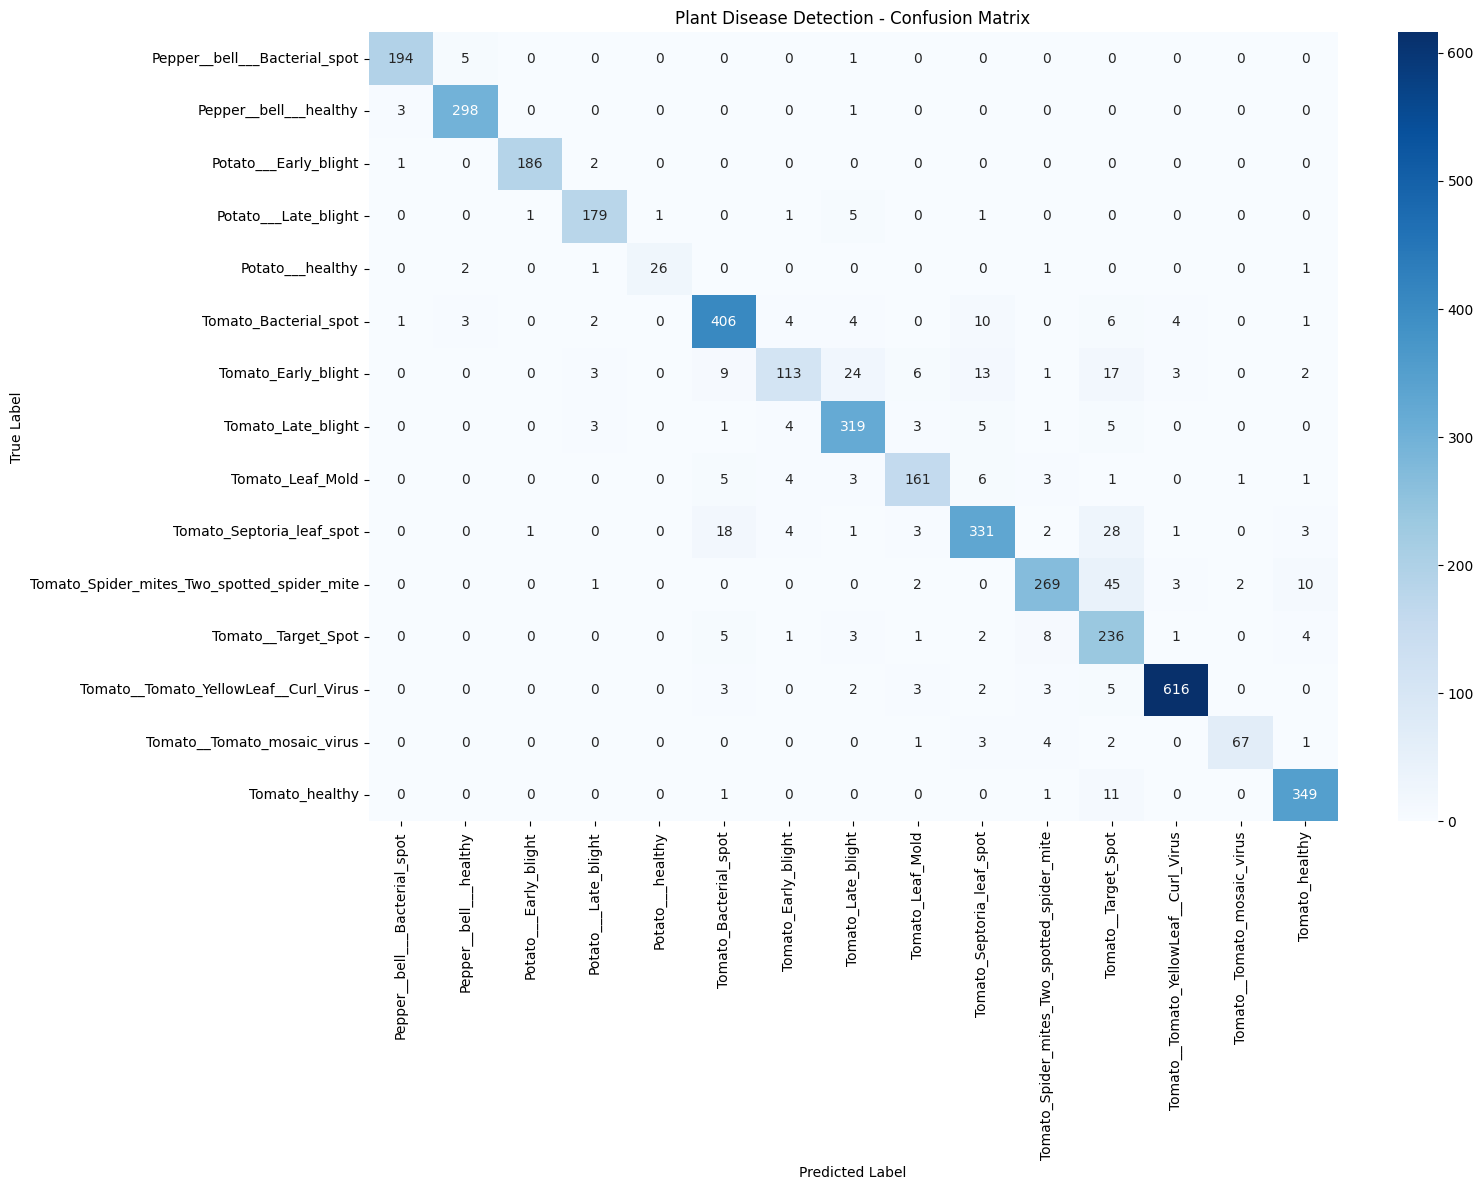

In [11]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

y_true = []
y_pred = []

for images, labels in val_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Correct evaluation accuracy:", accuracy_score(y_true, y_pred))

print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=range(len(class_names)))

plt.figure(figsize=(16, 12))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Plant Disease Detection - Confusion Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


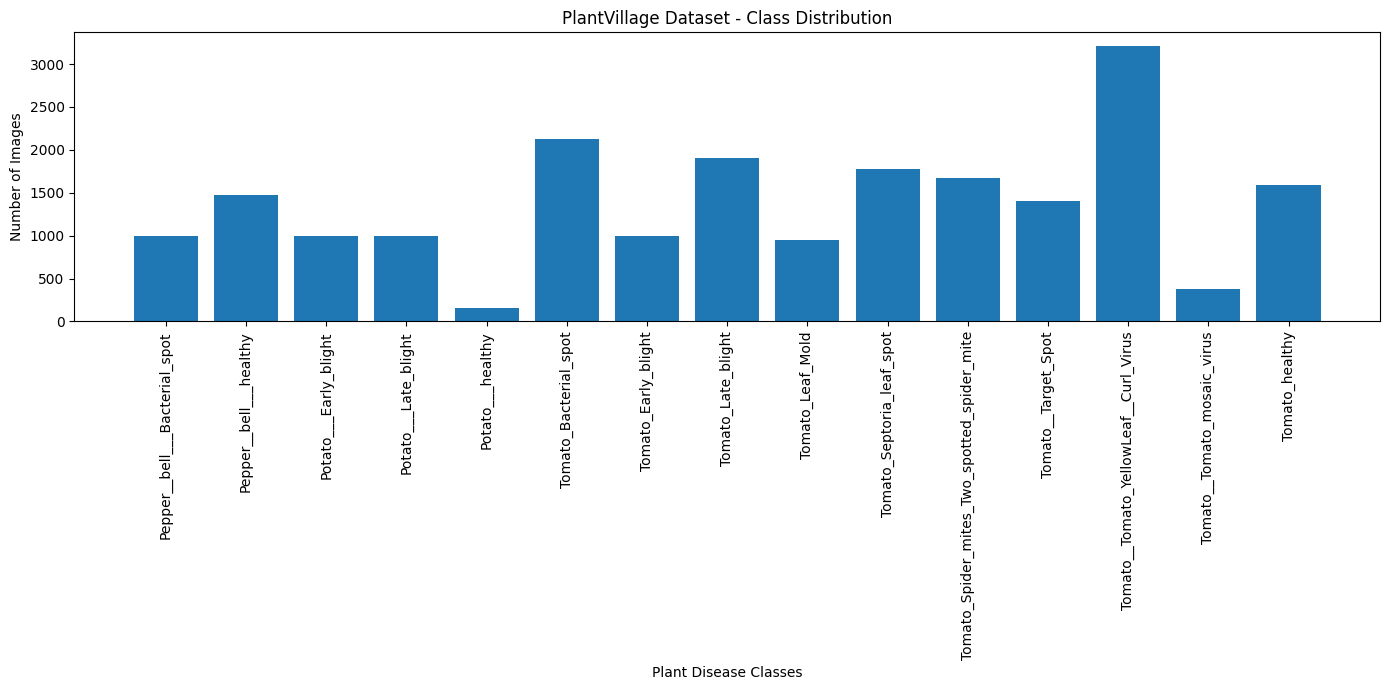

Total images: 20639
Total classes: 15


In [12]:

import os
import matplotlib.pyplot as plt

class_counts = {
    class_name: len(os.listdir(os.path.join(DATASET_PATH, class_name)))
    for class_name in sorted(os.listdir(DATASET_PATH))
    if os.path.isdir(os.path.join(DATASET_PATH, class_name))
}

plt.figure(figsize=(14, 7))
plt.bar(class_counts.keys(), class_counts.values())
plt.title("PlantVillage Dataset - Class Distribution")
plt.xlabel("Plant Disease Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

print("Total images:", sum(class_counts.values()))
print("Total classes:", len(class_counts))


In [13]:

model.save("/kaggle/working/plant_disease_model.keras")
print("Model saved successfully!")


Model saved successfully!


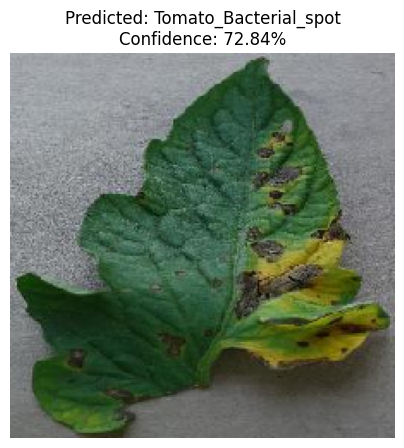

Actual class: Tomato_Early_blight
Predicted class: Tomato_Bacterial_spot
Confidence: 72.84%


In [14]:

import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

image_paths = []

for class_name in class_names:
    class_path = os.path.join(DATASET_PATH, class_name)

    for file_name in os.listdir(class_path):
        if file_name.lower().endswith((".jpg", ".jpeg", ".png")):
            image_paths.append(
                (os.path.join(class_path, file_name), class_name)
            )

image_path, actual_class = random.choice(image_paths)

img = tf.keras.utils.load_img(
    image_path,
    target_size=IMG_SIZE
)

img_array = tf.keras.utils.img_to_array(img)
prediction = model.predict(
    tf.expand_dims(img_array, axis=0),
    verbose=0
)[0]

predicted_index = np.argmax(prediction)
predicted_class = class_names[predicted_index]
confidence = prediction[predicted_index] * 100

plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")
plt.title(
    f"Predicted: {predicted_class}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.show()

print("Actual class:", actual_class)
print("Predicted class:", predicted_class)
print(f"Confidence: {confidence:.2f}%")


In [15]:

model.save("/kaggle/working/plant_disease_model.keras")
print("Model saved successfully!")


Model saved successfully!
